# Model 6 — Huber loss instead of MSE

An independent copy of `model2.ipynb`, which stays the baseline and is never modified. Everything starts from the original baseline: one hidden layer of 256, `embed_dim` 8, `weight_decay` 1e-4, the same data, split, seed and early stopping. The model class is the baseline's, so the initial weights are identical and **the loss is the only thing that differs**.

**Why.** Measured on the baseline's own predictions: 4.7% of validation rows are mates, and they carry **61% of the loss**. The model puts them at a median of 2,277 cp where the truth is 10,010+, and a static evaluator never will do better — a forced mate is a result of search, not a property of a position. So most of the gradient is spent on rows that cannot be learned, while the 0–300 cp band the eval bar and move classification depend on gets what is left. Huber makes a large error cost linearly rather than quadratically, which de-weights that tail without deleting a row.

**The prediction this run tests:** validation MSE gets *worse* and the median centipawn error gets *better*. If both move the same way, the reasoning was wrong.

Artifacts: `model6.pt`, `model6_history.json`, `model6_val_predictions.csv`.

Run top to bottom from a fresh kernel. `final_test.csv` is never opened here.

In [ ]:
import csv, json, time
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

# ml/ is the root whether the notebook is opened from ml/ or ml/notebooks/.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

from canonical import MAX_CP
from encode import CATEGORIES, EMBED_DIM, FEATURES, INPUT_SIZE, SQUARES, encode
from targets import S, to_cp, to_target

DATA = ROOT / "data"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

# Every file this notebook writes is named from here, so a copy cannot half-rename
# itself and overwrite another run's checkpoint.
RUN = "model6"
PARENT = "model2"           # the run this one varies by exactly one value
BASELINE = "model2"         # the original, which every run is also measured against
BASELINE_PARAMETERS = 132_969

# Four physical cores. The model is 133k parameters, so this is CPU work and a
# GPU would buy nothing; the thread count is pinned so epoch times stay
# comparable between runs rather than depending on what else is open.
torch.set_num_threads(4)
print(torch.__version__, "| inputs", INPUT_SIZE, "| run", RUN)

## Experiment parameters

The original baseline's values, with one change: the loss.

**Why `beta` is 1.0.** Beta is the error at which Huber switches from quadratic to linear, in *target* units, and this distribution puts it in the right place by measurement rather than by default. The median row's target is 0.286 and typical errors there run 0.2–0.3, so ordinary positions stay fully quadratic and lose none of their gradient. Mate rows sit near 3.0 and are currently missed by about 1.4, so they fall in the linear region and stop dominating. PyTorch's default happens to be correct here — for a reason worth writing down rather than inheriting silently.

In [2]:
CONFIG = {
    "run": RUN,
    "parent": PARENT,
    "changed_from_baseline": "MSE -> Huber (SmoothL1, beta=1.0)",
    "seed": 20261001,
    "embed_dim": EMBED_DIM,          # 8, from encode.py — not a second opinion
    "hidden": 256,
    "batch_size": 1024,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "max_epochs": 60,
    "patience": 6,                   # epochs without improvement before stopping
    "optimizer": "AdamW",
    "loss": "SmoothL1 on asinh(cp / S)",
    "huber_beta": 1.0,               # the quadratic-to-linear crossover, in target units
    "S": S,
}
CONFIG

{'run': 'model2_run4',
 'parent': 'model2',
 'changed_from_baseline': 'MSE -> Huber (SmoothL1, beta=1.0)',
 'seed': 20261001,
 'embed_dim': 8,
 'hidden': 256,
 'batch_size': 1024,
 'lr': 0.001,
 'weight_decay': 0.0001,
 'max_epochs': 60,
 'patience': 6,
 'optimizer': 'AdamW',
 'loss': 'SmoothL1 on asinh(cp / S)',
 'huber_beta': 1.0,
 'S': 1000}

## Dataset loading

Identical to the baseline, and deliberately so: if the data pipeline differed between runs, a difference in validation error would no longer be attributable to the one variable that changed.

In [3]:
def rows_of(split):
    """A split as (fen, target_value) pairs, in the file's own order.

    That order is (game_id, ply), inherited from the labeled file, so anything
    written back out alongside these rows lines up with the dataset.
    """
    with open(DATA / f"final_{split}.csv", newline="", encoding="utf-8") as fh:
        reader = csv.reader(fh)
        next(reader)                                   # fen,target_value
        return [(fen, int(target)) for fen, target in reader]


def load(rows):
    """Rows to tensors, encoded once up front.

    600,000 rows at 69 values is 41 MB as uint8, so the whole dataset lives in
    memory and every epoch after this is pure tensor arithmetic. Encoding inside
    the training loop would make a Python function call the bottleneck and hide
    what the model itself costs.

    Squares stay uint8 and are cast to long per batch: nn.Embedding needs int64
    indices, and holding 500,000 rows as int64 would be 256 MB for exactly the
    same information.
    """
    squares, flags, targets = [], [], []
    for fen, target in rows:
        position = encode(fen)
        squares.append(position.squares)
        flags.append((position.side_to_move,) + position.castling)
        # The one place centipawns become targets. Raw cp never enters a tensor,
        # so "loss is never computed on raw centipawns" holds by construction
        # rather than by remembering.
        targets.append(to_target(target))
    return (
        torch.from_numpy(np.array(squares, dtype=np.uint8)),
        torch.from_numpy(np.array(flags, dtype=np.float32)),
        torch.from_numpy(np.array(targets, dtype=np.float32)).unsqueeze(1),
    )


started = time.time()
train = load(rows_of("train"))       # the row list is not kept; only val's is
val_rows = rows_of("val")
val = load(val_rows)
# final_test.csv is deliberately not opened in this notebook. CW-164 froze it,
# and the simplest enforcement of that is its absence.
print(f"loaded and encoded in {time.time() - started:.0f}s")
print("train", tuple(train[0].shape), tuple(train[1].shape), tuple(train[2].shape))
print("val  ", tuple(val[0].shape), tuple(val[1].shape), tuple(val[2].shape))

loaded and encoded in 19s
train (500000, 64) (500000, 5) (500000, 1)
val   (50000, 64) (50000, 5) (50000, 1)


In [4]:
# Against the dataset's own measured numbers. A mate fraction far from 4.7% or a
# side-to-move split far from 49.8% would mean the encoder and the CSV disagree
# about what a row is — the one failure that would otherwise train quietly and
# evaluate nonsense.
squares, flags, targets = train
assert squares.shape[1] + flags.shape[1] == FEATURES == 69
assert 0 <= int(squares.min()) and int(squares.max()) < CATEGORIES
assert set(flags.unique().tolist()) <= {0.0, 1.0}

print(f"target  mean {targets.mean():+.4f}  std {targets.std():.4f}  "
      f"min {targets.min():+.4f}  max {targets.max():+.4f}")
median = float(targets.abs().median())
print(f"        median |target| {median:.4f}  ->  {to_cp(median):.0f} cp")
mates = (targets.abs() > to_target(MAX_CP)).float().mean()
print(f"mate band        {100 * mates:.1f}% of rows (expected 4.7%)")
print(f"White to move    {100 * flags[:, 0].mean():.1f}% (expected 49.8%)")

target  mean +0.0582  std 0.7998  min -3.0637  max +3.0637
        median |target| 0.2861  ->  290 cp
mate band        4.7% of rows (expected 4.7%)
White to move    49.8% (expected 49.8%)


## Model architecture

The baseline's, unchanged — a shared embedding over the 13 square categories, flattened and concatenated with side to move and the four castling bits, through one hidden layer of 256 ReLU units, to a single output with no activation.

The construction order matters and is the baseline's: both layers built, then Kaiming applied. Every `nn.Linear` draws from the global RNG when constructed, so this run starts from **exactly the same weights** as `model2` did — which is what makes the loss the only difference between them.

In [5]:
class Model2(nn.Module):
    """Embedding(13, embed_dim) shared across all 64 squares, flattened and
    concatenated with the five binary inputs, through one hidden ReLU layer, to
    a single output.

    The output carries no activation. Evaluations are signed, and the target
    spans roughly -3.06 to +3.06 after the asinh transform, so anything that
    bounded the output below that range would cap the model's own range.
    """

    def __init__(self, categories=CATEGORIES, embed_dim=CONFIG["embed_dim"],
                 hidden=CONFIG["hidden"]):
        super().__init__()
        self.embed = nn.Embedding(categories, embed_dim)
        self.hidden = nn.Linear(SQUARES * embed_dim + 5, hidden)
        self.out = nn.Linear(hidden, 1)
        # Kaiming with the ReLU gain, which is what this layer actually feeds.
        # PyTorch's default assumes leaky_relu with a = sqrt(5) and leaves the
        # activations smaller than they should be.
        nn.init.kaiming_uniform_(self.hidden.weight, nonlinearity="relu")
        nn.init.zeros_(self.hidden.bias)

    def forward(self, squares, flags):
        x = self.embed(squares.long()).flatten(1)      # (B, 64, E) -> (B, 64E)
        x = torch.cat([x, flags], dim=1)               # (B, 64E + 5)
        return self.out(torch.relu(self.hidden(x)))


torch.manual_seed(CONFIG["seed"])
model = Model2()

# The encoder's layout and the layer's width have to agree, or CW-236's C++
# evaluator would be porting a different model than the one trained.
assert model.hidden.in_features == SQUARES * CONFIG["embed_dim"] + 5
parameters = sum(p.numel() for p in model.parameters())
CONFIG["parameters"] = parameters
print(model)
print(f"\n{parameters:,} parameters — "
      f"{100 * parameters / BASELINE_PARAMETERS:.1f}% of the baseline's "
      f"{BASELINE_PARAMETERS:,}")
print(f"{len(train[0]) / parameters:.1f} training rows each")

Model2(
  (embed): Embedding(13, 8)
  (hidden): Linear(in_features=517, out_features=256, bias=True)
  (out): Linear(in_features=256, out_features=1, bias=True)
)

132,969 parameters — 100.0% of the baseline's 132,969
3.8 training rows each


## Optimizer, loss, and the validation pass

**Two losses, with different jobs.** `criterion` is Huber: it is what the gradients come from and what the kept checkpoint is selected on, because a run must be selected on what it optimises. `mse` is computed over the same validation pass purely so this run stays comparable with the ones trained on MSE — a Huber number and an MSE number are not the same quantity, and putting them in one column would silently rank them against each other.

The real comparison is neither: median absolute error in centipawns is loss-independent, and that is what the later cells report.

In [6]:
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"],
                              weight_decay=CONFIG["weight_decay"])
# Below an error of beta this is MSE/2 and above it absolute error, so the mate
# rows stop contributing in proportion to the square of a gap they will never
# close. nn.SmoothL1Loss rather than nn.HuberLoss: the two differ by a factor of
# beta in the loss VALUE, not in the gradient direction, and SmoothL1 is the one
# whose scale stays comparable to the MSE numbers already recorded.
criterion = nn.SmoothL1Loss(beta=CONFIG["huber_beta"])
mse = nn.MSELoss()


@torch.no_grad()
def evaluate(data, chunk=8192):
    """Returns (training criterion, plain MSE) over a whole split.

    Both in one pass, so the cost is the same as reporting either alone.
    """
    model.eval()
    squares, flags, targets = data
    total_criterion = total_mse = 0.0
    for i in range(0, len(squares), chunk):
        predicted = model(squares[i:i + chunk], flags[i:i + chunk])
        actual = targets[i:i + chunk]
        total_criterion += criterion(predicted, actual).item() * len(predicted)
        total_mse += mse(predicted, actual).item() * len(predicted)
    return total_criterion / len(squares), total_mse / len(squares)


val_loss, val_mse = evaluate(val)
print(f"val huber at init  {val_loss:.4f}")
print(f"val MSE   at init  {val_mse:.4f}   (the baseline's was 0.7239)")
print(f"target variance    {val[2].var():.4f}")

val huber at init  0.2566
val MSE   at init  0.7239   (the baseline's was 0.7239)
target variance    0.6350


## Training loop

The baseline's, with one addition: every epoch records plain MSE beside the training criterion, and the history file carries both. Early stopping and the kept checkpoint still follow the criterion being optimised.

For reference: `model2` reached **0.25692 MSE at epoch 10**, `model3` (two layers of 187) **0.24644 at epoch 10**. The number to watch here is not this run's loss — it is `val_mse`, and then the centipawn table below it.

In [7]:
CHECKPOINT = MODELS / f"{RUN}.pt"
HISTORY = MODELS / f"{RUN}_history.json"

generator = torch.Generator().manual_seed(CONFIG["seed"])
squares, flags, targets = train
n, batch = len(squares), CONFIG["batch_size"]

history, best, best_mse, best_epoch = [], float("inf"), None, 0
started = time.time()

for epoch in range(1, CONFIG["max_epochs"] + 1):
    model.train()
    # Seeded shuffle, so the run reproduces from the dataset files alone.
    order = torch.randperm(n, generator=generator)
    running = 0.0
    for i in range(0, n, batch):
        index = order[i:i + batch]
        optimizer.zero_grad()
        loss = criterion(model(squares[index], flags[index]), targets[index])
        loss.backward()
        optimizer.step()
        running += loss.item() * len(index)

    train_loss = running / n
    val_loss, val_mse = evaluate(val)
    history.append({"epoch": epoch, "train": train_loss,
                    "val": val_loss, "val_mse": val_mse})
    marker = ""

    # Selected on the criterion being optimised, not on the reported MSE.
    if val_loss < best:
        best, best_mse, best_epoch, marker = val_loss, val_mse, epoch, "  <- best"
        torch.save({"state_dict": model.state_dict(), "config": CONFIG,
                    "epoch": epoch, "val_loss": val_loss, "val_mse": val_mse},
                   CHECKPOINT)

    print(f"epoch {epoch:3}  train {train_loss:.5f}  val {val_loss:.5f}"
          f"  mse {val_mse:.5f}  {time.time() - started:5.0f}s{marker}")

    if epoch - best_epoch >= CONFIG["patience"]:
        print(f"\nstopping: no improvement in {CONFIG['patience']} epochs")
        break

HISTORY.write_text(json.dumps({"config": CONFIG, "best_epoch": best_epoch,
                               "best_val": best, "best_val_mse": best_mse,
                               "history": history}, indent=2))
print(f"\nbest huber {best:.5f} at epoch {best_epoch}  (its MSE {best_mse:.5f}) "
      f"— saved to {CHECKPOINT.name}")

epoch   1  train 0.22566  val 0.21499  mse 0.62488     15s  <- best
epoch   2  train 0.19564  val 0.16246  mse 0.45554     32s  <- best
epoch   3  train 0.13178  val 0.12016  mse 0.31541     48s  <- best
epoch   4  train 0.10889  val 0.10454  mse 0.26988     65s  <- best
epoch   5  train 0.10233  val 0.10201  mse 0.26403     83s  <- best
epoch   6  train 0.09937  val 0.10124  mse 0.26150    104s  <- best
epoch   7  train 0.09803  val 0.09874  mse 0.25575    118s  <- best
epoch   8  train 0.09679  val 0.09931  mse 0.25790    128s
epoch   9  train 0.09534  val 0.09869  mse 0.25702    138s  <- best
epoch  10  train 0.09440  val 0.10134  mse 0.25914    147s
epoch  11  train 0.09333  val 0.10048  mse 0.25974    156s
epoch  12  train 0.09192  val 0.10114  mse 0.26093    165s
epoch  13  train 0.09100  val 0.10005  mse 0.25880    174s
epoch  14  train 0.08967  val 0.10029  mse 0.25752    183s
epoch  15  train 0.08848  val 0.09966  mse 0.25776    194s

stopping: no improvement in 6 epochs

best

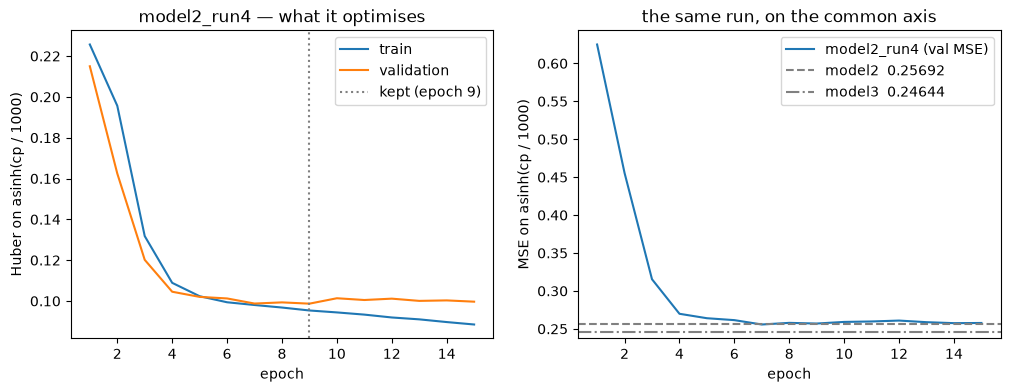

In [8]:
import matplotlib.pyplot as plt

epochs = [h["epoch"] for h in history]
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
left.plot(epochs, [h["train"] for h in history], label="train")
left.plot(epochs, [h["val"] for h in history], label="validation")
left.axvline(best_epoch, color="grey", linestyle=":",
             label=f"kept (epoch {best_epoch})")
left.set(xlabel="epoch", ylabel="Huber on asinh(cp / 1000)",
         title=f"{RUN} — what it optimises")
left.legend()

# The same run in MSE, which is the axis every earlier run is recorded on.
right.plot(epochs, [h["val_mse"] for h in history], label=f"{RUN} (val MSE)")
right.axhline(0.25692, color="grey", linestyle="--", label="model2  0.25692")
right.axhline(0.24644, color="grey", linestyle="-.", label="model3  0.24644")
right.set(xlabel="epoch", ylabel="MSE on asinh(cp / 1000)",
          title="the same run, on the common axis")
right.legend()
plt.show()

## Validation error in centipawns — the comparison that counts

Loss-independent, so this is the one place `model6` and the MSE-trained runs can be compared without an asterisk.

The baseline: median **173.9** cp, mean **618.1** cp, sign disagreement **23.2%**.

The hypothesis is that the median improves while the mean barely moves — the mean is almost entirely the mate rows, which this loss has deliberately stopped chasing.

In [9]:
model.load_state_dict(torch.load(CHECKPOINT, weights_only=True)["state_dict"])
model.eval()
with torch.no_grad():
    predicted = torch.cat([model(val[0][i:i + 8192], val[1][i:i + 8192])
                           for i in range(0, len(val[0]), 8192)])

predicted_cp = S * torch.sinh(predicted.squeeze(1))
actual_cp = S * torch.sinh(val[2].squeeze(1))
error = (predicted_cp - actual_cp).abs()

print(f"median absolute error  {error.median():8.1f} cp   (baseline 173.9)")
print(f"mean   absolute error  {error.mean():8.1f} cp   (baseline 618.1)")
disagree = ((predicted_cp > 0) != (actual_cp > 0)).float().mean()
print(f"sign disagreement      {100 * disagree:8.1f}%   (baseline 23.2)")

median absolute error     164.2 cp   (baseline 173.9)
mean   absolute error     602.0 cp   (baseline 618.1)
sign disagreement          21.7%   (baseline 23.2)


In [10]:
# Bucketed by the magnitude of the true evaluation, which is where this run has
# to show its effect: the point of Huber was to move gradient OUT of the mate
# band and INTO the band games are decided in. A win on the average alone would
# not be the thing that was argued for.
#
# The baseline's numbers, for each row below:
#   mate rows        2,347 (4.7%)   median 8389.4   sign  6.6%
#   |actual| < 100  16,637 (33.3%)  median   74.5   sign 41.5%
#   100 - 300        9,038 (18.1%)  median  126.8   sign 26.1%
#   300 - 1000      20,042 (40.1%)  median  299.8   sign 10.6%
#   above 1000       1,936 ( 3.9%)  median  619.8   sign  2.2%
is_mate = actual_cp.abs() > MAX_CP


def report(label, mask):
    if not mask.any():
        return
    chosen = error[mask]
    wrong = ((predicted_cp[mask] > 0) != (actual_cp[mask] > 0)).float().mean()
    print(f"{label:16} n {int(mask.sum()):6,} ({100 * mask.float().mean():4.1f}%)  "
          f"median {chosen.median():7.1f}  mean {chosen.mean():8.1f}  "
          f"sign {100 * wrong:5.1f}%")


report("mate rows", is_mate)
report("cp rows only", ~is_mate)
print()
for low, high, label in [(0, 100, "|actual| < 100"), (100, 300, "100 - 300"),
                         (300, 1000, "300 - 1000"), (1000, 10 ** 9, "above 1000")]:
    report(label, ~is_mate & (actual_cp.abs() >= low) & (actual_cp.abs() < high))

share = error[is_mate].sum() / error.sum()
print(f"\nthe mate rows carry {100 * share:.0f}% of the total absolute error "
      f"(baseline 58%)")

mate rows        n  2,347 ( 4.7%)  median  8740.7  mean   7792.5  sign   7.7%
cp rows only     n 47,653 (95.3%)  median   152.3  mean    247.8  sign  22.3%

|actual| < 100   n 16,637 (33.3%)  median    73.1  mean    116.9  sign  38.9%
100 - 300        n  9,064 (18.1%)  median   118.2  mean    155.2  sign  24.6%
300 - 1000       n 20,016 (40.0%)  median   279.8  mean    347.2  sign   9.5%
above 1000       n  1,936 ( 3.9%)  median   527.0  mean    779.4  sign   2.1%

the mate rows carry 61% of the total absolute error (baseline 58%)


## Real against predicted, one row per validation position

Written out so the error can be looked at outside the notebook — sorted, filtered, opened in a spreadsheet — rather than only summarised by the numbers above.

`actual_cp` is the dataset's `target_value`, taken from the CSV as the integer it is rather than round-tripped through the transform, so the comparison carries none of our own arithmetic. For the 4.7% of rows that are mates, that value is the mate-band encoding (10,010 to 10,680) rather than a centipawn score the engine reported — hence `is_mate`, which is the column to filter on before reading any average.

In [11]:
PREDICTIONS = MODELS / f"{RUN}_val_predictions.csv"

# load() preserved the order it was given and the predictions were built by
# walking the tensors in order, so row i of each is the same position. The
# assert is here because a silent misalignment would look like a badly trained
# model rather than like a bug.
assert len(val_rows) == len(predicted_cp)

with open(PREDICTIONS, "w", newline="", encoding="utf-8") as fh:
    writer = csv.writer(fh)
    writer.writerow(("fen", "actual_cp", "predicted_cp", "error_cp", "is_mate"))
    for (fen, actual), prediction in zip(val_rows, predicted_cp.tolist()):
        writer.writerow((fen, actual, round(prediction, 1),
                         round(prediction - actual, 1),
                         int(abs(actual) > MAX_CP)))

print(f"{len(val_rows):,} rows -> {PREDICTIONS}  "
      f"({PREDICTIONS.stat().st_size / 1e6:.1f} MB)")
with open(PREDICTIONS, encoding="utf-8") as fh:
    for _ in range(4):
        print("  " + next(fh).rstrip())

50,000 rows -> c:\Users\Uziel\Desktop\Projects\Chess Project\ml\models\model2_run4_val_predictions.csv  (3.9 MB)
  fen,actual_cp,predicted_cp,error_cp,is_mate
  r2qk1nr/1pp2ppp/p1pb4/4p3/3PP1b1/4BN2/PPP2PPP/RN1QK2R b KQkq - 0 7,54,-1.0,-55.0,0
  2kr3r/1pp1npp1/p1p2q1p/4N2b/4P3/2P1B2P/PPQN1PP1/R4RK1 b - - 0 14,-162,-245.9,-83.9,0
  2k5/2p1npp1/p1p4p/1p5b/2N1PP2/2Pr3P/PP3BP1/5RK1 w - - 0 21,340,251.9,-88.1,0


## Every run so far

Reads the history files, not the notebooks, so no other run is touched or re-run.

Ranked on **validation MSE**, which every run has — the MSE-trained ones because it is what they optimised, this one because it is recorded alongside. The `loss` column says which runs were actually selected on that number and which were not, because ranking a run on something it never optimised is a comparison with a footnote, not a verdict.

In [ ]:
runs = {path.name.replace("_history.json", ""): json.loads(path.read_text())
        for path in sorted(MODELS.glob("*_history.json"))}


def common(entry):
    """Validation MSE, whatever the run was trained on.

    Older histories predate the extra column, and for those best_val IS the MSE
    — they were trained on it.
    """
    return entry.get("best_val_mse", entry["best_val"])


base = common(runs[BASELINE])
print(f"{'run':16} {'val MSE':>9}  {'epoch':>5}  {'params':>8}  "
      f"{'vs model2':>10}   {'loss':<10} changed")
for name, entry in sorted(runs.items(), key=lambda kv: common(kv[1])):
    config = entry["config"]
    loss = "Huber" if "SmoothL1" in config.get("loss", "") else "MSE"
    print(f"{name:16} {common(entry):9.5f}  {entry['best_epoch']:5}  "
          f"{config.get('parameters', 0):8,}  {common(entry) - base:+10.5f}   "
          f"{loss:<10} {config.get('changed_from_baseline') or '—'}")

fig, ax = plt.subplots(figsize=(7, 4))
for name, entry in runs.items():
    ax.plot([h["epoch"] for h in entry["history"]],
            [h.get("val_mse", h["val"]) for h in entry["history"]],
            label=name, linewidth=2 if name == RUN else 1,
            linestyle="-" if name in (RUN, BASELINE) else "--")
ax.set(xlabel="epoch", ylabel="MSE on asinh(cp / 1000)",
       title="validation MSE, every run")
ax.legend()
plt.show()